# Model 1: Logistic Regression

**MMF 1922 · Explainable AI · Group presentation**
Dataset: UCI "Default of Credit Card Clients" (id 350)


---
## Part 0: Understand the problem

**The context (given)**

- A bank in Taiwan has records for **30,000 credit card clients** covering April to September 2005.
- For each client we know **23 things**: their credit limit, some demographics, and six months of repayment status, bill amounts and payment amounts.
- We also know whether each client defaulted on their payment the following month.
- Compare 3 models on this data: logistic regression (the baseline), XGBoost and a neural network. The presentation topic is explainable AI.

### How logistic regression works

Needed for Steps 9 and 10, so it is worth understanding now.

**1. The model adds up a score.** Each feature $x_j$ gets a weight $\beta_j$ (its *coefficient*):

$$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k$$

**2. It squashes the score into a probability** with the sigmoid function:

$$p = \frac{1}{1 + e^{-z}}$$

**3. Rearranging** shows what the coefficients mean:

$$\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$$

The left side is the **log-odds** of default. "Training" the model means finding the $\beta$ values that fit the data best.

---
## Step 1: Set up the tools

**Goal:** Import the libraries needed and fix the settings that all three notebooks share.

**Key ideas**

- **pandas** handles tables, **numpy** handles maths, **matplotlib** draws charts, **scikit-learn** (`sklearn`) does the machine learning.
- A **random seed** (`RANDOM_STATE`) makes anything random, like the train/test split, come out the same every time you run it.

These are the scikit-learn tools this notebook uses. Your job is to work out which `sklearn` module each one is imported from.

| Tool | Used in |
|---|---|
| `train_test_split` | Step 5 |
| `ColumnTransformer` | Step 6 |
| `StandardScaler`, `OneHotEncoder` | Step 6 |
| `Pipeline` | Step 7 |
| `LogisticRegression` | Step 7 |
| `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `roc_auc_score`, `roc_curve`, `ConfusionMatrixDisplay` | Step 8 |


Run this once to install `xlrd`, the package pandas needs to read the `.xls` data file.

In [1]:
%pip install -q xlrd

In [2]:
# Step 1: imports and shared settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from matplotlib.patches import Patch

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)

#Shared by all 3 models: keep these the same for all 3
RANDOM_STATE = 42
TEST_SIZE = 0.20

#Chart Colours
BLUE = "#2a78d6"   # lowers default risk
RED = "#e34948"    # raises default risk
GREY = "#8a8985"

---
## Step 2: Load the data

**Goal:** Load the dataset and store the inputs and the output in two separate variables.

**Key ideas**

- **Features** are the inputs (what we know about a client). The **target** is the output (did they default?).
- The convention is capital `X` for the features (a table with many columns) and lowercase `y` for the target (a single column).
- **Shared setup:** all three models must use the same `X` and `y`, so this step matches the neural network notebook exactly. We read the `.xls` file from the group repo, rename the target to `DEFAULT`, and drop `ID` (a client number, which says nothing about default risk).
- `header=1` tells pandas to take the column names from the file's *second* row. The first row of the spreadsheet is an extra label row (`X1`, `X2`, …, `Y`).

In [3]:
# Step 2: load the data (shared setup: same X and y as the other two models)
# The NN notebook sits in the repo's notebooks/ folder, so it uses "../data/default of credit card clients.xls".
# Same file; the path is different only because this notebook sits next to the repo folder.
DATA_PATH = "explainable-credit-risk/default of credit card clients.xls"

df = pd.read_excel(DATA_PATH, header=1)

df = df.rename(
    columns={"default payment next month": "DEFAULT"}
)

X = df.drop(columns=["ID", "DEFAULT"])   # the 23 features
y = df["DEFAULT"]                        # 1 = defaulted the following month

print("Features: ", X.shape)
print("Target: ", y.shape)
X.head()

Features:  (30000, 23)
Target:  (30000,)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


---
## Step 3: Understand the data

**Goal:** Explore the data before modelling it.

**Data dictionary (given).** The 23 feature columns are:

| Column(s) | Meaning |
|---|---|
| `LIMIT_BAL` | Credit limit, in New Taiwan dollars |
| `SEX` | 1 = male, 2 = female |
| `EDUCATION` | 1 = graduate school, 2 = university, 3 = high school, 4 = other |
| `MARRIAGE` | 1 = married, 2 = single, 3 = other |
| `AGE` | Age in years |
| `PAY_0`, `PAY_2` … `PAY_6` | Repayment status per month. `PAY_0` = September (most recent), `PAY_6` = April. −1 = paid on time, 1 = one month late, 2 = two months late, and so on. −2 and 0 are not in the official documentation; they are commonly read as "no card use" and "paid the minimum" |
| `BILL_AMT1` … `BILL_AMT6` | Bill statement amount per month (1 = most recent) |
| `PAY_AMT1` … `PAY_AMT6` | Amount actually paid per month (1 = most recent) |
| `DEFAULT` (target) | 1 = defaulted the following month, 0 = did not. Renamed from `default payment next month` in Step 2 |

Naming note: the file calls the most recent repayment column `PAY_0` and then jumps to `PAY_2` (there is no `PAY_1`). We keep the original names so our feature names match the other two models.

In [4]:
# Step 3a: size, missing values, summary statistics
print("Rows, Columns: ", X.shape)
print("Missing values: ", int(X.isna().sum().sum()))

X.describe().T.round(1)

Rows, Columns:  (30000, 23)
Missing values:  0


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_0,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_5,30000.0,-0.3,1.1,-2.0,-1.0,0.0,0.0,8.0


### 3b. How balanced is the target?

Default rate: 22.1%


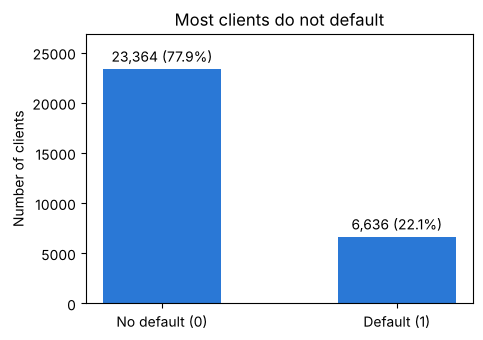

In [5]:
# Step 3b: target balance
counts = y.value_counts().sort_index()   # index 0 = no default, 1 = default
print(f"Default rate: {y.mean():.1%}")

fig, ax = plt.subplots(figsize = (5, 3.5))
bars = ax.bar(["No default (0)", "Default (1)"], counts.values, color = BLUE, width = 0.5)
ax.bar_label(bars, labels=[f"{c:,} ({c / len(y):.1%})" for c in counts.values], padding=3)
ax.set_ylabel("Number of clients")
ax.set_title("Most clients do not default")
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

The classes are imbalanced: about 4 in 5 clients do not default. Hold on to that. It means a "model" that simply says *nobody defaults* is right about 78% of the time while being useless. We come back to this in Step 8.

### 3c. Do the category codes match the dictionary?

In [6]:
# Step 3c: category codes
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print (f"--- {col} ---")
    print (X[col].value_counts().sort_index().to_string())
    print()


--- SEX ---
SEX
1    11888
2    18112

--- EDUCATION ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51

--- MARRIAGE ---
MARRIAGE
0       54
1    13659
2    15964
3      323



`EDUCATION` contains the codes 0, 5 and 6, and `MARRIAGE` contains 0. None of those are in the documentation. Step 4 decides what to do with them.

---
## Step 4: Clean the data

**Goal:** Decide what to do with the undocumented category codes found in 3c.

**Key ideas:** There are three reasonable options for codes nobody can explain:

- **Drop** those rows
- **Keep** them as their own categories
- **Merge** them into an existing "other" category

**Group decision: keep them.** The shared setup uses `X` exactly as it comes out of Step 2, so all three models see the same inputs and nothing is changed here. In Step 6 the one-hot encoder gives every code its own column (`EDUCATION_0`, `EDUCATION_5`, `EDUCATION_6`, `MARRIAGE_0`).

The catch: these are small groups (see the counts in 3c), so the coefficients for those columns rest on very few clients. Treat them with caution in Step 9.

---
## Step 5: Split into train and test

**Goal:** Hold back 20% of clients as a test set the model never sees during training.

**Key ideas**

- The model learns from the **training set**. The **test set** stands in for future clients.
- **`stratify`** keeps the default rate the same in both sets.
- **`random_state`** makes the split identical every run.
- **Shared setup:** all three notebooks use `test_size=0.20`, `stratify=y` and `random_state=42`, so every model is tested on exactly the same 6,000 clients.

In [7]:
# Step 5: train/test split (shared setup)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = TEST_SIZE,         # 0.20
    stratify = y,
    random_state = RANDOM_STATE    # 42
)

print(f"Train: {len(X_train):,} clients, default rate {y_train.mean():.1%}")
print(f"Test:  {len(X_test):,} clients, default rate {y_test.mean():.1%}")

Train: 24,000 clients, default rate 22.1%
Test:  6,000 clients, default rate 22.1%


---
## Step 6: Preprocess

**Goal:** Describe how to prepare the inputs: scale the numeric columns and one-hot encode the categories. This is the **shared preprocessing**, identical in all three notebooks.

**Key ideas**

**Scaling (`StandardScaler`).** Each numeric value becomes $\frac{x - \text{mean}}{\text{standard deviation}}$, i.e. "how many standard deviations from average". `LIMIT_BAL` is in the hundreds of thousands while `PAY_0` runs from −2 to 8; after scaling they are on the same footing, so their coefficients can be compared.

**One-hot encoding (`OneHotEncoder`).** Turns one category column into several 0/1 columns, one per category. The shared setup keeps **every** category (no `drop="first"`), so there is no reference group:

| Feature | New columns |
|---|---|
| `SEX` | `SEX_1`, `SEX_2` |
| `EDUCATION` | `EDUCATION_0` … `EDUCATION_6` (7 columns) |
| `MARRIAGE` | `MARRIAGE_0` … `MARRIAGE_3` (4 columns) |

- `handle_unknown="ignore"`: if the test set has a code the encoder never saw in training, that row gets all zeros instead of crashing.
- `sparse_output=False`: returns an ordinary table of numbers, which SHAP and LIME need later.

That makes 20 scaled numeric columns + 13 one-hot columns = **33 features**, the same 33 the XGBoost and neural network models see.

**Why no reference group still works.** The one-hot columns for a feature always add up to 1, so on their own they overlap with the intercept and the model can't decide how to split the effect between them. The mild L2 penalty in Step 7 settles that. The price: a single one-hot coefficient no longer means "compared with the reference group". Compare categories *within* a feature instead, e.g. `SEX_2` minus `SEX_1` is the gap in log-odds between women and men.

**`ColumnTransformer`** applies one transformer to some columns and another transformer to others.

In [8]:
# Step 6: describe the preprocessing (nothing is calculated yet)
# Shared setup: identical to the other two models
categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
]

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    verbose_feature_names_out=False,   # "SEX_2" instead of "categorical__SEX_2"
)

print(f"{len(numeric_features)} numeric features will be scaled")
print(f"{len(categorical_features)} categorical features will be one-hot encoded")

20 numeric features will be scaled
3 categorical features will be one-hot encoded


The scaler learns each feature's mean and standard deviation. If it learned them from all 30,000 clients, information about the test set would leak into training. Putting the preprocessing inside a `Pipeline` (next step) guarantees it learns from the training set only.

---
## Step 7: Train the model

**Goal:** Chain the preprocessing and the model together, then train on the training set.

**Key ideas**

- A **`Pipeline`** runs steps in order. Calling `.fit()` on it learns the preprocessing from the training data, transforms that data, then fits the model.
- Training logistic regression means finding the coefficients that make the observed outcomes most likely (**maximum likelihood**).
- scikit-learn adds a mild penalty on large coefficients by default (L2 regularisation, `C=1.0`). With 24,000 clients its effect is small.

In [9]:
# Step 7: build and train the model
model = Pipeline(steps = [
    ("prep", preprocessor), 
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)), 
])

model.fit(X_train, y_train) # learns scaling + coefficients from training data only
model 

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `ve

---
## Step 8: Evaluate — how well does it predict?

**Goal:** Measure performance on the test set, then look at the trade-off behind the yes/no threshold.

**Key ideas**

The model outputs a **probability of default**. A **threshold** turns that into a decision (flag the client if probability ≥ threshold).

| Metric | Question it answers |
|---|---|
| **Accuracy** | What share of all predictions were correct? |
| **Precision** | Of the clients we flagged, how many really defaulted? |
| **Recall** | Of the clients who really defaulted, how many did we catch? |
| **F1** | One number balancing precision and recall |
| **ROC-AUC** | How well does the model *rank* defaulters above non-defaulters, across all thresholds? 0.5 = coin flip, 1.0 = perfect |

**Shared setup:** all three models are scored with the same `evaluate_classifier` function, at the standard 0.50 threshold (what `model.predict()` uses).

### 8a. Predictions and metrics

In [10]:
# Step 8a: predictions and metrics on the TEST set

# Shared setup: every model is scored with this exact function
def evaluate_classifier(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }

THRESHOLD = 0.50   # same as model.predict(), which the other notebooks use

proba_test = model.predict_proba(X_test)[:, 1]      # column 1 = probability of default
pred_test = (proba_test >= THRESHOLD).astype(int)   # 1 = flagged

metrics = evaluate_classifier(y_test, pred_test, proba_test)

naive_accuracy = 1 - y_test.mean()   # always predicts "no default"
print(f"Naive benchmark accuracy: {naive_accuracy:.3f}\n")
pd.Series(metrics, name = "Logistic Regression").round(3).to_frame()

Naive benchmark accuracy: 0.779



,Logistic Regression
Accuracy,0.809
ROC-AUC,0.710
Precision,0.692
Recall,0.244
F1,0.361


### 8b. Confusion matrix

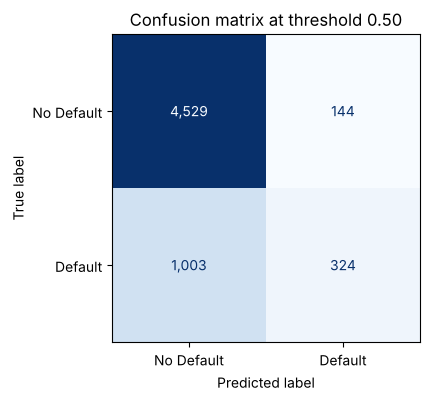

In [11]:
# Step 8b: confusion matrix
fig, ax = plt.subplots(figsize = (4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test,
    display_labels = ["No Default", "Default"],
    cmap = "Blues", colorbar = False, values_format = ",", ax = ax,
)

ax.set_title(f"Confusion matrix at threshold {THRESHOLD:.2f}")
plt.show()

**The confusion matrix** shows where the errors are. Rows are what actually happened, columns are what the model predicted.

### 8c. ROC curve

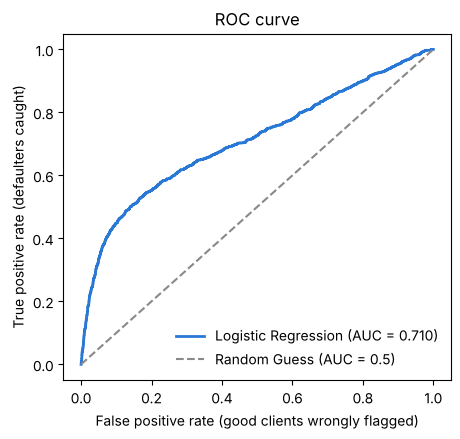

In [12]:
# Step 8c: ROC curve
fpr, tpr, _ = roc_curve(y_test, proba_test)

fig, ax = plt.subplots(figsize = (5,4.5))
ax.plot(fpr, tpr, color = BLUE, linewidth = 2, label = f"Logistic Regression (AUC = {metrics['ROC-AUC']:.3f})")
ax.plot([0,1], [0,1], color = GREY, linestyle = '--', label = "Random Guess (AUC = 0.5)")
ax.set_xlabel("False positive rate (good clients wrongly flagged)")
ax.set_ylabel("True positive rate (defaulters caught)")
ax.set_title("ROC curve")
ax.legend(loc="lower right", frameon=False)
plt.show()

**The ROC curve** plots the trade-off at every threshold: how many real defaulters we catch (vertical) against how many good clients we wrongly flag (horizontal). The closer the curve bends to the top-left corner, the better. The dashed line is random guessing.

### 8d. The threshold trade-off

In [13]:
# Step 8d: how do the metrics change with the threshold?
rows = []
for t in [0.50, 0.40, 0.30, 0.20]:
    pred_t = (proba_test >= t).astype(int)
    rows.append({
        'threshold': t,
        'share flagged': pred_t.mean(),
        'precision': precision_score(y_test, pred_t, zero_division=0),
        'recall': recall_score(y_test, pred_t),
        'f1': f1_score(y_test, pred_t),
    })

pd.DataFrame(rows).set_index('threshold').round(3)

,share flagged,precision,recall,f1
threshold,,,,
0.5,0.078,0.692,0.244,0.361
0.4,0.132,0.631,0.378,0.473
0.3,0.183,0.552,0.457,0.500
0.2,0.477,0.319,0.690,0.437


The threshold is a business decision, not a modelling decision. With imbalanced data, 0.50 is usually too strict and the model misses many defaulters. Lowering the threshold catches more of them at the cost of more false alarms. The table below shows the trade-off.

---
## Step 9: Explain the model

**Goal:** Read the coefficients to find what drives default across *all* clients.

**Key ideas**

- **Numeric features** were scaled, so a coefficient is the change in log-odds for a **one-standard-deviation** increase. Bigger absolute value = stronger influence.
- **One-hot features** have no reference group in the shared setup (Step 6), so compare categories *within* the same feature: e.g. `SEX_2` minus `SEX_1` is the gap in log-odds between women and men. The small undocumented groups (`EDUCATION_0`, `EDUCATION_5`, `EDUCATION_6`, `MARRIAGE_0`) rest on very few clients, so don't read much into their coefficients.
- **Odds ratio** = $e^{\text{coefficient}}$. 1.5 means the odds of default are 50% higher; 0.8 means 20% lower; 1 means no effect.
- **Caution:** when features are strongly correlated with each other, the model can't tell which one deserves the credit, so their individual coefficients can come out with strange signs or sizes.

### 9a. The coefficient table

In [14]:
# Step 9a: coefficient table
feature_out = model.named_steps["prep"].get_feature_names_out()   # 33 names after preprocessing
coefs = model.named_steps["clf"].coef_[0]                         # 33 coefficients
intercept = model.named_steps["clf"].intercept_[0]                # beta_0

coef_table = pd.DataFrame({
    "feature": feature_out,
    "coefficient": coefs,
    "odds_ratio": np.exp(coefs),
}).sort_values("coefficient", key=abs, ascending=False).reset_index(drop=True)

print(f"Intercept: {intercept:.3f}")
coef_table.round(3)

Intercept: -1.219


,feature,coefficient,odds_ratio
0,EDUCATION_5,-1.040,0.353
1,MARRIAGE_0,-0.995,0.370
2,PAY_0,0.661,1.937
3,EDUCATION_4,-0.639,0.528
4,SEX_2,-0.557,0.573
5,SEX_1,-0.438,0.645
6,EDUCATION_1,0.386,1.471
7,BILL_AMT1,-0.321,0.726
8,EDUCATION_2,0.288,1.334
9,EDUCATION_0,-0.287,0.751


### 9b. Chart the biggest effects

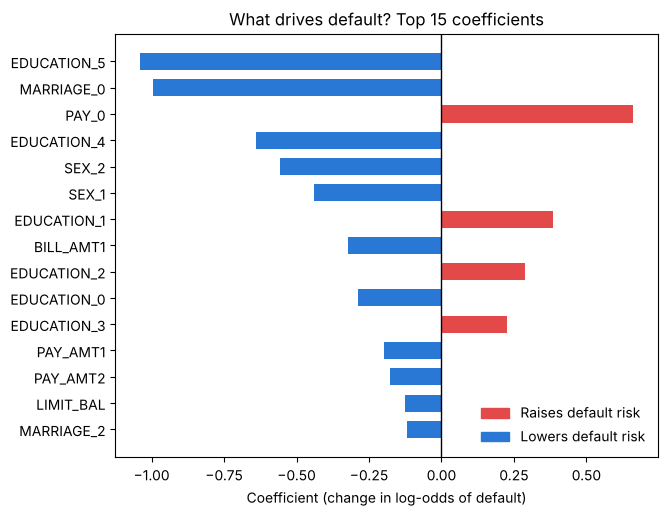

In [15]:
# Step 9b: horizontal bar chart of the 15 largest coefficients
top = coef_table.head(15).iloc[::-1]   # reversed so the biggest is at the top

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top["feature"], top["coefficient"],
        color=[RED if c > 0 else BLUE for c in top["coefficient"]], height=0.65)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Coefficient (change in log-odds of default)")
ax.set_title("What drives default? Top 15 coefficients")
ax.legend(handles=[Patch(color=RED, label="Raises default risk"),
                   Patch(color=BLUE, label="Lowers default risk")],
          loc="lower right", frameon=False)
plt.show()

### 9c. Are the bill amounts correlated?

In [16]:
# Step 9c: correlation between the six bill amounts
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
X_train[bill_cols].corr().round(2)

,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
BILL_AMT1,1.00,0.95,0.90,0.86,0.83,0.80
BILL_AMT2,0.95,1.00,0.94,0.89,0.86,0.83
BILL_AMT3,0.90,0.94,1.00,0.93,0.89,0.86
BILL_AMT4,0.86,0.89,0.93,1.00,0.94,0.90
BILL_AMT5,0.83,0.86,0.89,0.94,1.00,0.95
BILL_AMT6,0.80,0.83,0.86,0.90,0.95,1.00


---
## Step 10: Explain one prediction (local)

**Goal:** Explain why the model gave *one specific client* their probability, and prove the explanation is exact by rebuilding the prediction by hand.

**Key ideas**

Go back to the score formula: $z = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$

- Each term $\beta_j x_j$ is that feature's **contribution** for this client, where $x_j$ is the client's value *after preprocessing*.
- Positive contributions push towards default; negative ones push away.
- Intercept + all contributions = $z$ (the log-odds). The sigmoid of $z$ = the probability.
- **One-hot columns need care.** With no reference group (Step 6), part of the baseline sits inside their coefficients, which is why `SEX_1` and `SEX_2` are *both* negative. Read a category's contribution against the other categories of the same feature, not on its own.


### 10a. Rebuild one prediction by hand

In [17]:
# Step 10a: rebuild one client's prediction by hand
client_position = int(np.argmax(proba_test))   # riskiest test client; try np.argmin for the safest

x_client = X_test.iloc[[client_position]]                     # 1-row table
x_scaled = model.named_steps["prep"].transform(x_client)[0]   # values after preprocessing

contributions = coefs * x_scaled                  # beta_j * x_j for each feature
log_odds = intercept + contributions.sum()        # z
probability = 1 / (1 + np.exp(-log_odds))         # sigmoid(z)

print(f"Rebuilt by hand:  {probability:.4f}")
print(f"From the model:   {proba_test[client_position]:.4f}")
print(f"Actually:         {'defaulted' if y_test.iloc[client_position] == 1 else 'did not default'}")

Rebuilt by hand:  0.9927
From the model:   0.9927
Actually:         defaulted


### 10b. Which features drove this prediction?

In [18]:
# Step 10b: contribution table
local_table = pd.DataFrame({
    "feature": feature_out,
    "scaled_value": x_scaled,
    "coefficient": coefs,
    "contribution": contributions,
}).sort_values("contribution", key=abs, ascending=False).reset_index(drop=True)

display(x_client)   # the client's raw values
print(f"Intercept (starting point): {intercept:.3f}")
local_table.head(10).round(3)

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
4387,90000,1,2,1,35,8,7,6,5,4,...,108539,106001,103816,101878,0,0,0,0,0,0


Intercept (starting point): -1.219


,feature,scaled_value,coefficient,contribution
0,PAY_0,7.136,0.661,4.717
1,PAY_2,5.951,0.092,0.548
2,PAY_3,5.164,0.095,0.488
3,SEX_1,1.000,-0.438,-0.438
4,EDUCATION_2,1.000,0.288,0.288
5,PAY_4,4.494,0.061,0.275
6,BILL_AMT1,0.837,-0.321,-0.269
7,BILL_AMT2,0.876,0.097,0.085
8,LIMIT_BAL,-0.597,-0.125,0.075
9,PAY_AMT1,-0.348,-0.200,0.070


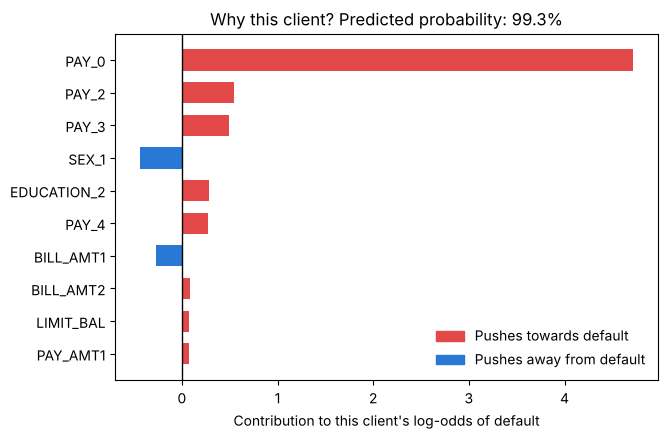

In [19]:
# Step 10c: chart of this client's top 10 contributions
top_local = local_table.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_local["feature"], top_local["contribution"],
        color=[RED if c > 0 else BLUE for c in top_local["contribution"]], height=0.65)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Contribution to this client's log-odds of default")
ax.set_title(f"Why this client? Predicted probability: {probability:.1%}")
ax.legend(handles=[Patch(color=RED, label="Pushes towards default"),
                   Patch(color=BLUE, label="Pushes away from default")],
          loc="lower right", frameon=False)
plt.show()

<details>
<summary>Hint</summary>

Reuse your code from 9b, swapping in `local_table` and the `"contribution"` column. An f-string puts the probability in the title: `f"Predicted probability: {probability:.1%}"`.

</details>

**Check yourself:** Change `client_position` to the *safest* client (`np.argmin` instead of `np.argmax`) and re-run 10a to 10c. Which features are doing the work now?

<details>
<summary>Compare your Think first answer (question 1)</summary>

The coefficients were learned on preprocessed inputs: scaled numbers and 0/1 category columns. Multiplying a coefficient by a raw value (e.g. a credit limit of 200,000) mixes two different units and gives nonsense.

</details>

> **Ask Claude:** *"How is this per-client breakdown related to SHAP values? Why can't I do the same thing directly for XGBoost?"*

---
## Step 11: Save the results

**Goal:** Save this model's test metrics to a file so all three models can go into one comparison table later.

In [20]:
# Step 11: save the metrics

# TODO: `results` = a one-row table with: model name ("Logistic Regression"), the threshold, and every metric
# TODO: save it as "results_logistic_regression.csv" (without the row index)
# TODO: display results

<details>
<summary>Hint</summary>

`pd.DataFrame([{...}])` makes a one-row table from one dictionary. Inside a dictionary, `**metrics` unpacks all the metric entries. Use `.to_csv("file name", index=False)`.

</details>

**Check yourself:** The CSV appears in the same folder as this notebook (in Colab: the Files panel).

---
## Step 12: Takeaways

Fill these in from your own results. They become the Model 1 slides.

> **To update after switching to the shared setup:** the performance numbers below are unchanged (same split, same metrics, same 324 of 1,327 defaulters caught). What changed is in Explainability and Limitations: `PAY_1` is now called `PAY_0`; the largest coefficients are now `EDUCATION_5` (−1.04), `MARRIAGE_0` (−1.00) and `PAY_0` (+0.66), because the undocumented codes are no longer merged into `EDUCATION_4`; `BILL_AMT1` and `BILL_AMT2` are now −0.32 and +0.10; and in Step 10 the biggest push away from default is now `SEX_1` (−0.44), ahead of `BILL_AMT1` (−0.27).

**Performance (question 1: how well does it predict?)**

- ROC AUC on the test set: 0.710. Better than a coin flip (0.5) but not great. If I pick one defaulter and one non-defaulter at random, the model gives the defaulter the higher score about 71% of the time.
- Accuracy 0.809 versus a naive benchmark of 0.779. That's only 3 points better than saying "nobody defaults", so accuracy is not the number to judge this model on.
- At a 0.50 threshold the model catches 24.4% of real defaulters (324 out of 1,327). The other 1,003 get through.
- The threshold I would recommend, and why: 0.30. Recall goes from 24% to 46% and precision is still 55%, so more than half the clients we flag really do default. It also has the best F1 in my table (0.500). I wouldn't go down to 0.20 because we'd be flagging 48% of all clients and only about 1 in 3 of those flags would be right. This assumes a missed defaulter costs the bank more than a false alarm. If a flag meant something harsh like cutting the client's limit, I'd move back up to 0.40.

**Explainability (question 2: how easily can we explain it?)**

- The three strongest drivers of default: going by coefficient size they are EDUCATION_4 (-1.12), PAY_1 (+0.66) and BILL_AMT1 (-0.33). PAY_1 is the real one. It's the only one of the three that raises risk, and being one standard deviation later on the most recent payment multiplies the odds of default by 1.94. I don't put much weight on the other two. EDUCATION_4 is the "other" group I merged in Step 4 and it's only 468 of the 30,000 clients. BILL_AMT1 is mixed up with the other bill columns (see limitations). The next one that makes sense is PAY_AMT1 (-0.21): paying more last month lowers the risk.
- One sentence a manager would understand: "The best warning sign is how late a client was on their latest payment. Someone about one month further behind has nearly double the odds of defaulting next month."
- What the local explanation in Step 10 showed: I took the riskiest client in the test set (predicted 99.3%, and they did default) and rebuilt the probability by hand from the intercept and the coefficients. I got 0.9927, the same as the model. Nearly all of it came from PAY_1, which added +4.71 to the log-odds on its own because this client was about 7 standard deviations above average on lateness. PAY_2, PAY_3 and PAY_4 added a bit more, and the only real push the other way was BILL_AMT1 (-0.28). So for any single client we can say exactly why they got their score, with no approximation.

**Strengths of logistic regression** (your own words)

- I can read the model straight off the coefficient table. The sign gives the direction and the odds ratio gives the size, and I don't need an extra tool like SHAP to get there.
- The explanation for one client is exact, not an estimate. My by-hand number matched the model to four decimals, which is what you'd want if you had to tell a client why they were declined.
- When it does flag someone at 0.50 it's right 69% of the time, so the flags it does raise are fairly reliable.
- It's simple, quick to train and gives the same answer every run, so it's a fair baseline for XGBoost and the neural network.

**Limitations** (think about Step 3 question 2, Step 9c, and what a straight-line model can't capture)

- Prediction is only okay. AUC is 0.71, and at the default threshold it misses about three quarters of defaulters while barely beating the naive benchmark on accuracy.
- The six bill amounts are 0.80 to 0.95 correlated with each other (Step 9c), so the model can't tell them apart. BILL_AMT1 comes out at -0.33 and BILL_AMT2 at +0.12, which makes no sense if you read them one at a time. The coefficients are easy to read, but for these columns I wouldn't trust what they say.
- It treats PAY_1 to PAY_6 as ordinary numbers, so going from -2 to -1 counts the same as going from 1 to 2 months late. But -2 and 0 aren't even in the official documentation, and they are codes more than amounts of lateness. A straight line can't deal with that.
- It only adds things up. Each feature has one fixed effect no matter what the other features are doing, so it can't pick up combinations (like a high bill together with a late payment) or effects that level off unless we build those columns ourselves. That's where I'd expect XGBoost and the neural network to gain.
- The biggest coefficient in the whole model (EDUCATION_4) belongs to a group of undocumented codes that I lumped together, so I can't really say what it means. Being transparent doesn't help much when the input itself is unclear.

> **Ask Claude:** *"Here are my takeaways for Model 1: [paste]. Is anything I wrote not supported by my results? What am I missing?"*

---

### Reusing this workbook for Models 2 and 3

| Step | XGBoost | Neural network |
|---|---|---|
| 1–5 | Same. Keep `RANDOM_STATE` and `TEST_SIZE` | Same |
| 6 Preprocess | Think: do trees need scaling? | Think: does a neural network need scaling? |
| 7 Train | New model | New model |
| 8 Evaluate | Same code | Same code |
| 9–10 Explain | No coefficients. What replaces them? | No coefficients. What replaces them? |
| 11 Save | New model name and file name | New model name and file name |